In [ ]:
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error


# Load data
df = pd.read_csv("../data/car_data.csv")

# Features and target
X = df.drop("selling_price", axis=1)
y = df["selling_price"]


# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# Identify columns
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns

numerical_cols = X_train.select_dtypes(
    exclude=["object"]
).columns


# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numerical_cols
        )
    ]
)


# Random Forest model
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# Train
model.fit(X_train, y_train)

print("✅ FINAL MODEL TRAINED")


# Evaluate
predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)

print("R² Score:", r2)
print("MAE:", mae)


# Save FINAL model
joblib.dump(
    model,
    "../model/car_price_model.pkl"
)

print("✅ FINAL MODEL SAVED")


# Test with two different cars
sample1 = X_test.iloc[[0]]
sample2 = X_test.iloc[[1]]

print("\nTest prediction 1:", model.predict(sample1)[0])
print("Actual price 1:", y_test.iloc[0])

print("\nTest prediction 2:", model.predict(sample2)[0])
print("Actual price 2:", y_test.iloc[1])

✅ FINAL MODEL TRAINED
R² Score: 0.5759219316541587
MAE: 118578.96574957484
✅ FINAL MODEL SAVED

Test prediction 1: 177613.33333333337
Actual price 1: 165000

Test prediction 2: 405596.6616666666
Actual price 2: 250000


In [34]:
import joblib

model_data = {
    "model": model,
    "columns": X.columns.tolist()
}

joblib.dump(model_data, "../model/car_price_model.pkl")

print("New model saved successfully!")

New model saved successfully!


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:


X = df.drop("selling_price", axis=1)
y = df["selling_price"]


X = pd.get_dummies(X, drop_first=True)

print(X.shape)
print("Data prepared successfully!")

(4340, 1503)
Data prepared successfully!


In [37]:
import joblib

joblib.dump(model, "../model/car_price_model.pkl")

print("✅ NEW MODEL SAVED")

✅ NEW MODEL SAVED


In [38]:
from sklearn.metrics import r2_score, mean_absolute_error

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)

print("R² Score:", r2)
print("MAE:", mae)

R² Score: 0.7963472450432831
MAE: 0.2520367933851738


In [ ]:
model.fit(X_train, y_train)

print("✅ Model training completed!")

✅ Model training completed!


In [54]:
import joblib

joblib.dump(model, "../model/car_price_model.pkl")

print("✅ FINAL MODEL SAVED")

✅ FINAL MODEL SAVED


In [52]:
model.fit(X_train, y_train)

print("✅ FINAL MODEL TRAINED")

✅ FINAL MODEL TRAINED


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Find categorical and numerical columns
categorical_cols = X_train.select_dtypes(include=["object"]).columns
numerical_cols = X_train.select_dtypes(exclude=["object"]).columns

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

# Final ML pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("✅ Pipeline created")

✅ Pipeline created


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="passthrough"
)

In [42]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical:", categorical_cols)
print("Numeric:", numeric_cols)

Categorical: []
Numeric: ['year', 'km_driven', 'name_Ambassador Classic 2000 Dsz', 'name_Ambassador Grand 1800 ISZ MPFI PW CL', 'name_Audi A4 1.8 TFSI', 'name_Audi A4 2.0 TDI', 'name_Audi A4 2.0 TDI 177 Bhp Premium Plus', 'name_Audi A4 3.0 TDI Quattro', 'name_Audi A4 30 TFSI Technology', 'name_Audi A4 35 TDI Premium', 'name_Audi A4 35 TDI Premium Plus', 'name_Audi A4 New  2.0 TDI Multitronic', 'name_Audi A5 Sportback', 'name_Audi A6 2.0 TDI  Design Edition', 'name_Audi A6 2.0 TDI Premium Plus', 'name_Audi A6 2.7 TDI', 'name_Audi A6 2.8 FSI', 'name_Audi A8 4.2 TDI', 'name_Audi A8 L 3.0 TDI quattro', 'name_Audi Q3 2.0 TDI Quattro Premium Plus', 'name_Audi Q3 35 TDI Quattro Technology', 'name_Audi Q5 2.0 TDI', 'name_Audi Q5 2.0 TFSI Quattro', 'name_Audi Q5 2.0 TFSI Quattro Premium Plus', 'name_Audi Q5 3.0 TDI Quattro Technology', 'name_Audi Q7 35 TDI Quattro Premium', 'name_Audi RS7 2015-2019 Sportback Performance', 'name_BMW 3 Series 320d Luxury Line', 'name_BMW 3 Series 320d Sport', 'na

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 3472
Testing rows: 868


In [43]:
X = df.drop("selling_price", axis=1)
y = df["selling_price"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['name', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Target:
selling_price


In [7]:
df["Price"].min(), df["Price"].max()

(np.float64(5011.27), np.float64(99982.59))

In [46]:
import joblib

# Save the trained model
joblib.dump(lr, "model/car_price_model.pkl")

print("Model saved successfully!")

NameError: name 'lr' is not defined

In [45]:
sample = X.iloc[[0]]

prediction = model.predict(sample)

print(prediction)

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [56]:
model = joblib.load("car_price_model.pkl")

In [48]:
import joblib

joblib.dump(rf, "car_price_model.pkl")

NameError: name 'rf' is not defined

In [47]:
from sklearn.model_selection import GridSearchCV

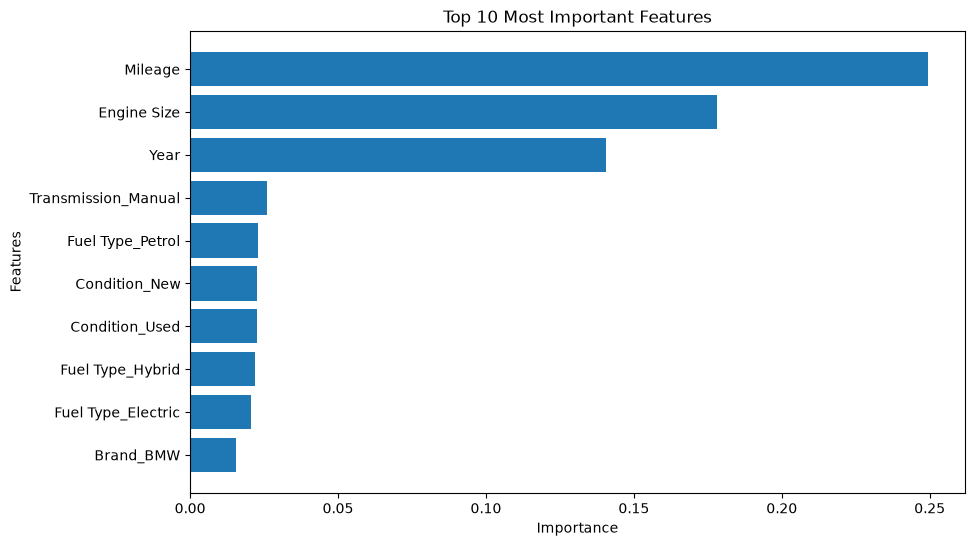

In [53]:
plt.figure(figsize=(10,6))

plt.barh(
    importance["Feature"][:10],
    importance["Importance"][:10]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Most Important Features")

plt.gca().invert_yaxis()

plt.show()

In [52]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
2,Mileage,0.249493
1,Engine Size,0.178139
0,Year,0.140565
12,Transmission_Manual,0.025917
11,Fuel Type_Petrol,0.022915
13,Condition_New,0.022720
14,Condition_Used,0.022719
10,Fuel Type_Hybrid,0.021989
9,Fuel Type_Electric,0.020546
3,Brand_BMW,0.015590


In [51]:
best_model = results.sort_values(
    by="R2 Score",
    ascending=False
)

best_model

,Model,R2 Score,MAE,RMSE
0,Linear Regression,-0.019769,23877.143119,27794.413124
3,Gradient Boosting,-0.021860,23813.881092,27822.895412
2,Random Forest,-0.072490,24609.298373,28503.824869
1,Decision Tree,-0.982085,31778.517680,38749.646038


In [50]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred),
        r2_score(y_test, gb_pred)
    ],

    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, dt_pred),
        mean_absolute_error(y_test, rf_pred),
        mean_absolute_error(y_test, gb_pred)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, dt_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
        np.sqrt(mean_squared_error(y_test, gb_pred))
    ]
})

results.sort_values(by="R2 Score", ascending=False)

,Model,R2 Score,MAE,RMSE
0,Linear Regression,-0.019769,23877.143119,27794.413124
3,Gradient Boosting,-0.021860,23813.881092,27822.895412
2,Random Forest,-0.072490,24609.298373,28503.824869
1,Decision Tree,-0.982085,31778.517680,38749.646038


In [49]:
print("Gradient Boosting Results")
print("-" * 30)

print("R² Score :", r2_score(y_test, gb_pred))
print("MAE :", mean_absolute_error(y_test, gb_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, gb_pred)))

Gradient Boosting Results
------------------------------
R² Score : -0.021860080515818003
MAE : 23813.88109165115
RMSE : 27822.89541227996


In [ ]:
gb = GradientBoostingRegressor(random_state=42)

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

In [47]:
print("Random Forest Results")
print("-" * 30)

print("R² Score :", r2_score(y_test, rf_pred))
print("MAE :", mean_absolute_error(y_test, rf_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, rf_pred)))

Random Forest Results
------------------------------
R² Score : -0.07248954959771692
MAE : 24609.2983726
RMSE : 28503.82486855803


In [ ]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [45]:
print("Decision Tree Results")
print("-" * 30)

print("R² Score :", r2_score(y_test, dt_pred))
print("MAE :", mean_absolute_error(y_test, dt_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, dt_pred)))

Decision Tree Results
------------------------------
R² Score : -0.9820849622849066
MAE : 31778.51768
RMSE : 38749.646037722356


In [ ]:
dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

In [43]:
print("R² Score :", r2_score(y_test, lr_pred))
print("MAE :", mean_absolute_error(y_test, lr_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, lr_pred)))

R² Score : -0.019768995768104203
MAE : 23877.14311881309
RMSE : 27794.413123934646


In [42]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [40]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 42)
(500, 42)
(2000,)
(500,)


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [38]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 2500 non-null   int64  
 1   Engine Size          2500 non-null   float64
 2   Mileage              2500 non-null   int64  
 3   Brand_BMW            2500 non-null   bool   
 4   Brand_Ford           2500 non-null   bool   
 5   Brand_Honda          2500 non-null   bool   
 6   Brand_Mercedes       2500 non-null   bool   
 7   Brand_Tesla          2500 non-null   bool   
 8   Brand_Toyota         2500 non-null   bool   
 9   Fuel Type_Electric   2500 non-null   bool   
 10  Fuel Type_Hybrid     2500 non-null   bool   
 11  Fuel Type_Petrol     2500 non-null   bool   
 12  Transmission_Manual  2500 non-null   bool   
 13  Condition_New        2500 non-null   bool   
 14  Condition_Used       2500 non-null   bool   
 15  Model_5 Series       2500 non-null   bool   
 16 

In [37]:
X = pd.get_dummies(X, drop_first=True)

In [36]:
X = X.drop("Car ID", axis=1)

In [35]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [34]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 42)
(500, 42)
(2000,)
(500,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:

# ONE HOT ENCODING

X = pd.get_dummies(
    X,
    drop_first=True
)

X.head()

,Year,Engine Size,Mileage,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Mercedes,Brand_Tesla,Brand_Toyota,Fuel Type_Electric,...,Model_Model S,Model_Model X,Model_Model Y,Model_Mustang,Model_Prius,Model_Q5,Model_Q7,Model_RAV4,Model_X3,Model_X5
0,2016,2.3,114832,False,False,False,False,True,False,False,...,False,True,False,False,False,False,False,False,False,False
1,2018,4.4,143190,True,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
2,2013,4.5,181601,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
3,2011,4.1,68682,False,False,False,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
4,2009,2.6,223009,False,True,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [ ]:

X = X.drop("Car ID", axis=1)

X.head()

,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Model
0,Tesla,2016,2.3,Petrol,Manual,114832,New,Model X
1,BMW,2018,4.4,Electric,Manual,143190,Used,5 Series
2,Audi,2013,4.5,Electric,Manual,181601,New,A4
3,Tesla,2011,4.1,Diesel,Automatic,68682,New,Model Y
4,Ford,2009,2.6,Diesel,Manual,223009,Like New,Mustang


In [ ]:

# Features
X = df.drop("Price", axis=1)

# Target
y = df["Price"]

print("X Shape :", X.shape)
print("y Shape :", y.shape)

X Shape : (2500, 9)
y Shape : (2500,)


In [ ]:

for col in categorical_columns:
    print("=" * 50)
    print(f"{col}")
    print("=" * 50)
    print(df[col].unique())
    print()

Brand
<StringArray>
['Tesla', 'BMW', 'Audi', 'Ford', 'Honda', 'Mercedes', 'Toyota']
Length: 7, dtype: str

Fuel Type
<StringArray>
['Petrol', 'Electric', 'Diesel', 'Hybrid']
Length: 4, dtype: str

Transmission
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

Condition
<StringArray>
['New', 'Used', 'Like New']
Length: 3, dtype: str

Model
<StringArray>
[ 'Model X', '5 Series',       'A4',  'Model Y',  'Mustang',       'Q7',
       'Q5',    'Civic', 'Explorer',  'Model 3',   'Fiesta',       'X3',
      'GLA',       'A3',       'X5',  'C-Class',  'E-Class',     'CR-V',
    'Camry',   'Accord',      'GLC',  'Corolla',      'Fit',  'Model S',
    'Prius', '3 Series',     'RAV4',    'Focus']
Length: 28, dtype: str



In [ ]:

categorical_columns = X.select_dtypes(include="object").columns

categorical_columns

Index(['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model'], dtype='str')

In [ ]:
X.columns

Index(['Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission', 'Mileage',
       'Condition', 'Model'],
      dtype='str')

In [ ]:

# Car ID is only an identifier.
# It has no relationship with the selling price.

X = X.drop("Car ID", axis=1)

X.head()

,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Model
0,Tesla,2016,2.3,Petrol,Manual,114832,New,Model X
1,BMW,2018,4.4,Electric,Manual,143190,Used,5 Series
2,Audi,2013,4.5,Electric,Manual,181601,New,A4
3,Tesla,2011,4.1,Diesel,Automatic,68682,New,Model Y
4,Ford,2009,2.6,Diesel,Manual,223009,Like New,Mustang


In [ ]:

y.head()

0    26613.92
1    14679.61
2    44402.61
3    86374.33
4    73577.10
Name: Price, dtype: float64

In [ ]:

X.head()

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,Mustang


In [ ]:


# X contains all input features
X = df.drop("Price", axis=1)

# y contains the value we want to predict
y = df["Price"]

In [ ]:


df.dtypes

Car ID            int64
Brand               str
Year              int64
Engine Size     float64
Fuel Type           str
Transmission        str
Mileage           int64
Condition           str
Price           float64
Model               str
dtype: object

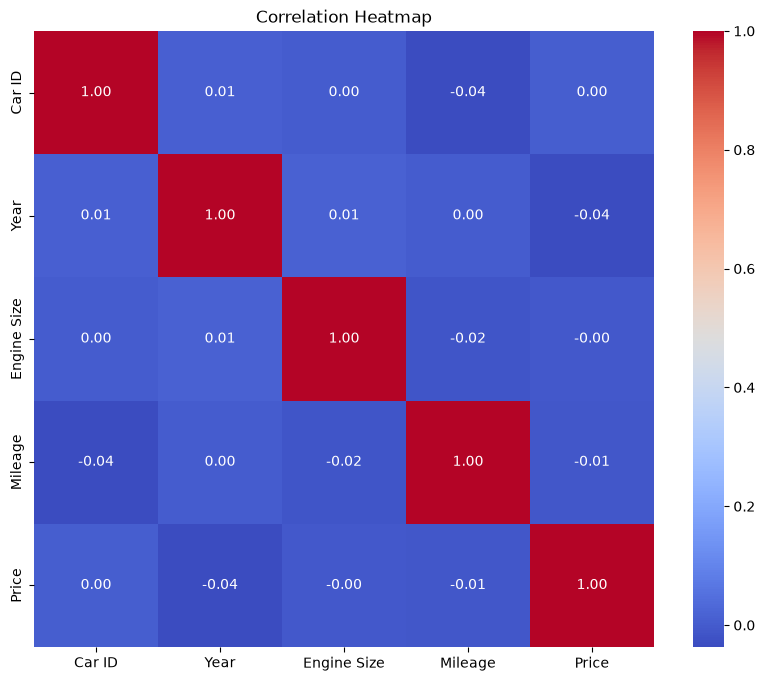

In [ ]:

numerical_df = df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(10,8))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

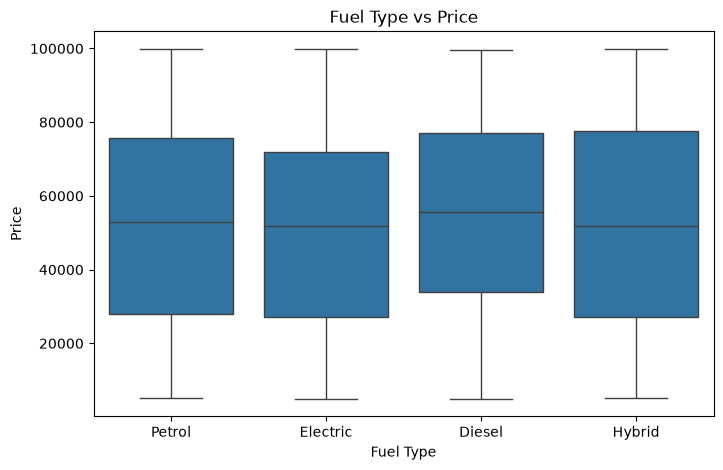

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Fuel Type",
    y="Price"
)

plt.title("Fuel Type vs Price")

plt.show()

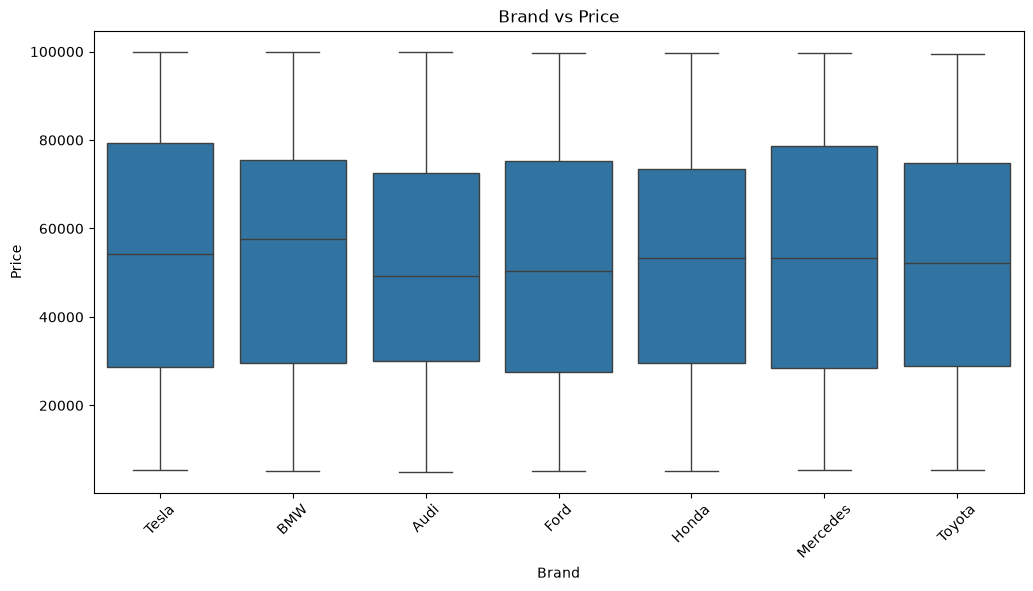

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="Brand",
    y="Price"
)

plt.title("Brand vs Price")

plt.xticks(rotation=45)

plt.show()

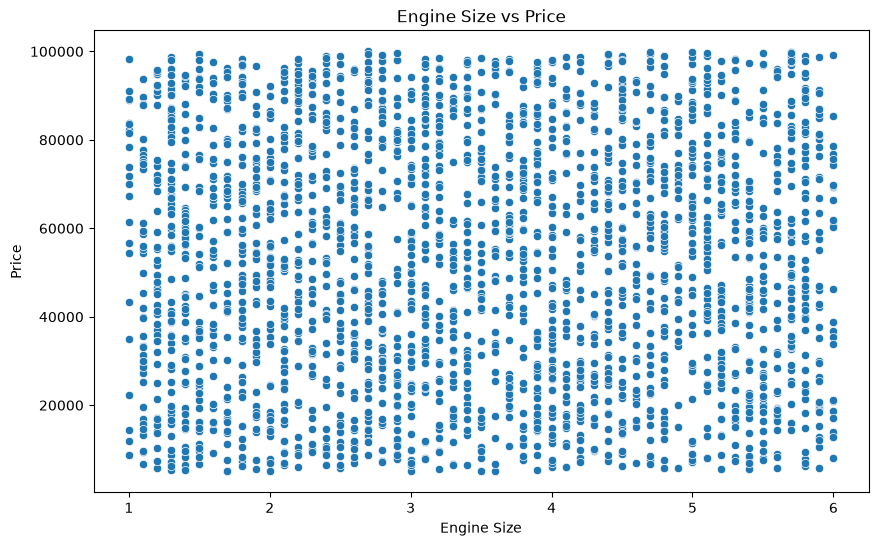

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Engine Size",
    y="Price"
)

plt.title("Engine Size vs Price")

plt.xlabel("Engine Size")

plt.ylabel("Price")

plt.show()

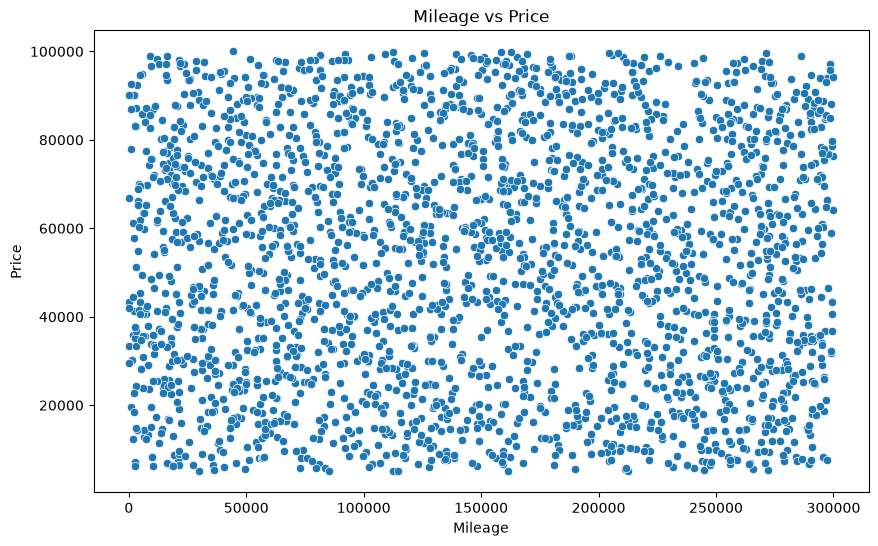

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Mileage",
    y="Price"
)

plt.title("Mileage vs Price")

plt.xlabel("Mileage")

plt.ylabel("Price")

plt.show()

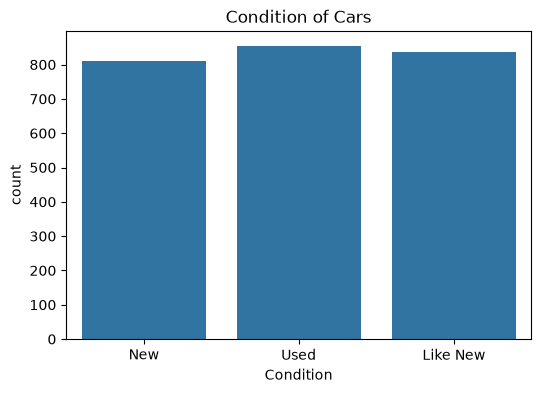

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Condition"
)

plt.title("Condition of Cars")

plt.show()

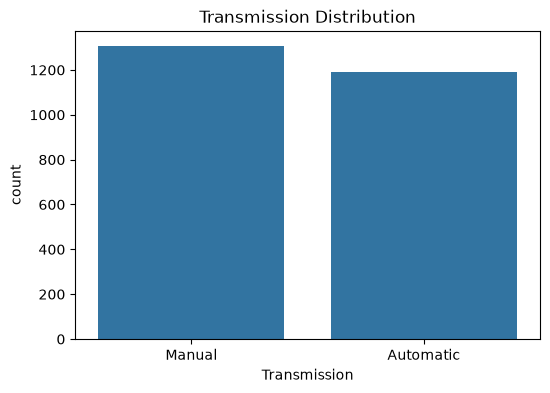

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Transmission"
)

plt.title("Transmission Distribution")

plt.show()

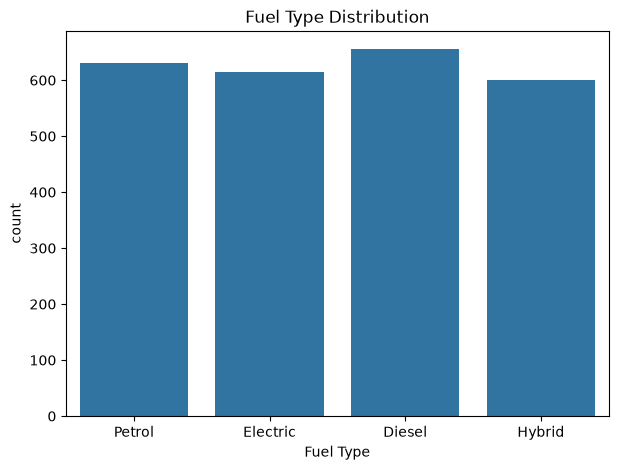

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Fuel Type"
)

plt.title("Fuel Type Distribution")

plt.show()

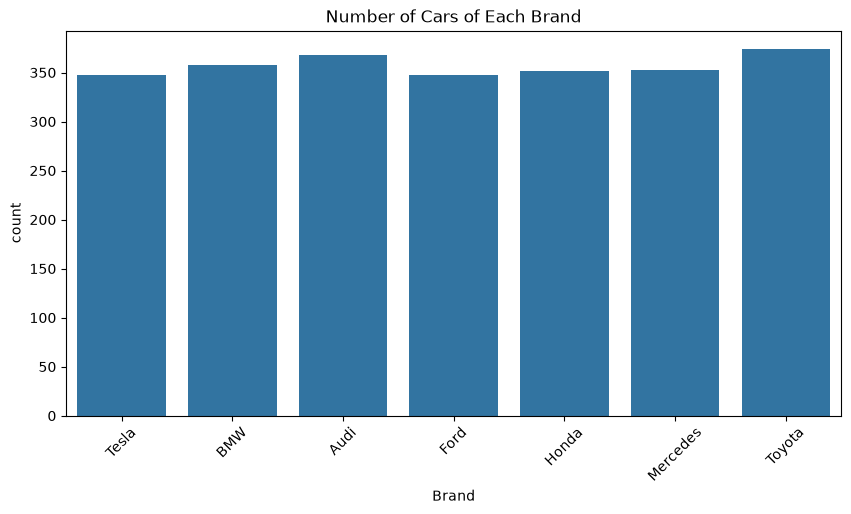

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Brand"
)

plt.title("Number of Cars of Each Brand")

plt.xticks(rotation=45)

plt.show()

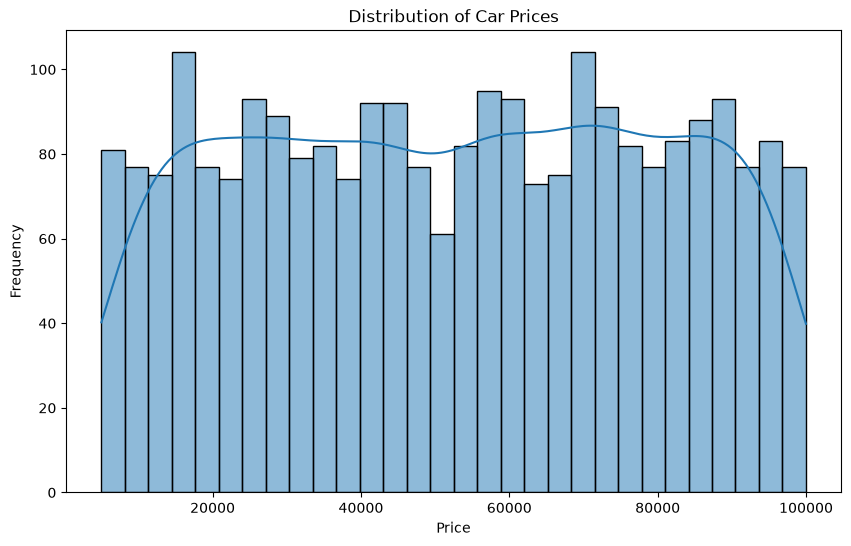

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Price",
    kde=True,
    bins=30
)

plt.title("Distribution of Car Prices")

plt.xlabel("Price")

plt.ylabel("Frequency")

plt.show()

# Exploratory Data Analysis (EDA)

## Objective

The objective of this project is to predict the **Price** of a car using machine learning.

### Target Variable
- Price

### Input Features
- Brand
- Model
- Year
- Engine Size
- Fuel Type
- Transmission
- Mileage
- Condition

In [11]:
df.nunique()

Car ID          2500
Brand              7
Year              24
Engine Size       51
Fuel Type          4
Transmission       2
Mileage         2490
Condition          3
Price           2499
Model             28
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64

In [8]:
df.describe()

,Car ID,Year,Engine Size,Mileage,Price
count,2500.00000,2500.0000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2011.6268,3.465240,149749.844800,52638.022532
std,721.83216,6.9917,1.432053,87919.952034,27295.833455
min,1.00000,2000.0000,1.000000,15.000000,5011.270000
25%,625.75000,2005.0000,2.200000,71831.500000,28908.485000
50%,1250.50000,2012.0000,3.400000,149085.000000,53485.240000
75%,1875.25000,2018.0000,4.700000,225990.500000,75838.532500
max,2500.00000,2023.0000,6.000000,299967.000000,99982.590000


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB


In [6]:
df.isnull().sum()

Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64

In [5]:
df.shape

(2500, 10)

In [9]:
import pandas as pd

df = pd.read_csv("../data/car_data.csv")

print(df.columns.tolist())

['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [2]:



import pandas as pd


import numpy as np


import matplotlib.pyplot as plt


import seaborn as sns


%matplotlib inline
import warnings
warnings.filterwarnings("ignore")